# Проект: Влияние приложения для медитации на время засыпания

Тема «Постановка и проверка гипотез» \
уровень: начальный

---

## Сценарий

Компания разработала мобильное приложение с вечерними медитациями. Чтобы понять, помогает ли оно быстрее засыпать,
провели небольшое исследование. **Около 50 добровольцев** в течение одной недели фиксировали, сколько минут им требуется,
чтобы заснуть (среднее за неделю). Затем в течение 4 недель они пользовались приложением и ещё одну неделю
снова фиксировали время засыпания.

Данные получены **выгрузкой из системы сбора анкет**, поэтому, как и в реальной работе, они могут содержать ошибки.
Перед анализом их нужно проверить и очистить.

**Бизнес-вопрос:** *сокращает ли использование приложения время засыпания?*

Вы работаете аналитиком и должны ответить на него с помощью проверки статистических гипотез.

## Описание данных

| Столбец | Описание |
|---|---|
| `participant_id` | Идентификатор участника |
| `age` | Возраст участника (полных лет) |
| `before_min` | Среднее время засыпания (мин) за неделю **до** использования приложения |
| `after_min` | Среднее время засыпания (мин) за неделю **после** 4 недель использования |

Данные **парные**: каждая строка — один и тот же человек, измеренный дважды.
Возрастных групп в исходных данных **нет**: их нужно сформировать самостоятельно (задание 2).

## Допущения (упрощения для учебного проекта)

- Участники независимы друг от друга.
- Уровень значимости $\alpha = 0.05$ для всех проверок.
- Контрольной группы нет, поэтому причинно-следственные выводы ограничены (это нужно будет отметить в выводах).
- Допустимые значения (используются при очистке): время засыпания от **5 до 180 минут**, возраст от **18 до 80 лет**.

## Правила выполнения

1. Ячейку с генерацией данных **не изменяйте**. Также **нет необходимости изучать её код**: в реальной работе у вас нет кода, создавшего выгрузку, и проблемы в данных нужно находить анализом самой таблицы.
2. Каждый график должен иметь заголовок, подписи осей и (если нужно) легенду.
3. Решения о гипотезах, очистке данных и выбор тестов нужно **обосновывать словами**, а не только кодом.
4. Выводы формулируйте на языке бизнеса: без фраз вида «отвергаем H₀» в итоговом заключении.
5. Ноутбук должен выполняться целиком сверху вниз без ошибок (**Kernel → Restart & Run All**).

## Критерии оценки

| № | Задание | Баллы |
|---|---|:---:|
| 1 | Формулировка гипотез | 2 |
| 2 | Аудит и очистка данных, формирование возрастных групп | 4 |
| 3 | Разведочный анализ и графики | 2 |
| 4 | Проверка нормальности | 2 |
| 5 | Парный t-критерий и доверительный интервал | 2 |
| 6 | Критерий Уилкоксона | 1 |
| 7 | Сравнение с ошибочным непарным тестом | 2 |
| 8 | Размер эффекта | 1 |
| 9 | Гипотеза о доле улучшивших | 1 |
| 10 | Итоговые выводы | 1 |
| 11 | Оформление проекта (репозиторий, `requirements.txt`, воспроизводимость) | 2 |
| | **Итого** | **20** |
| ★ | Бонусное задание | +2 |

## Подготовка

Импортируйте нужные библиотеки в ячейке ниже (часть уже указана). При необходимости добавьте свои.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy import stats

sns.set_theme(style="whitegrid")

ALPHA = 0.05   # уровень значимости

### Данные

Выполните ячейку ниже. **Не изменяйте её и не изучайте её код** (см. правила выше): фиксированное зерно генератора (`seed`) гарантирует, что у всех получатся одинаковые данные.

In [2]:
rng = np.random.default_rng(150)
n = 50

age = rng.integers(18, 61, size=n).astype(float)
before = rng.normal(35, 10, n)
effect = np.where(age < 35, -4, -1)
after = before + rng.normal(effect, 4.5)

df = pd.DataFrame({
    "participant_id": range(1, n + 1),
    "age": age,
    "before_min": np.clip(before.round(), 5, None).astype(object),
    "after_min": np.clip(after.round(), 5, None).astype(object),
})

# --- Имитация реальной выгрузки: в ней бывают сбои и ошибки ввода ---
df.loc[[3, 17], "after_min"] = np.nan
df.loc[29, "before_min"] = np.nan
df.loc[8, "after_min"] = -20
df.loc[22, "before_min"] = 999
df.loc[41, "after_min"] = 400
df.loc[12, "before_min"] = f"{float(df.loc[12, 'before_min']):.1f}".replace(".", ",")
df.loc[36, "after_min"] = f"{float(df.loc[36, 'after_min']):.1f}".replace(".", ",")
df.loc[[5, 14], "age"] = np.nan
df.loc[19, "age"] = 0
df.loc[33, "age"] = 150
df = pd.concat([df, df.loc[[10, 25]]], ignore_index=True)
df = df.sample(frac=1, random_state=1).reset_index(drop=True)

df.head(10)

,participant_id,age,before_min,after_min
0,32,52.0,31.0,26.0
1,3,42.0,30.0,32.0
2,43,30.0,30.0,24.0
3,33,31.0,28.0,18.0
4,31,30.0,28.0,25.0
5,46,54.0,24.0,21.0
6,34,150.0,33.0,29.0
7,39,24.0,28.0,25.0
8,45,19.0,56.0,57.0
9,20,0.0,35.0,30.0


---
## Задание 1. Формулировка гипотез (2 балла)

**Что нужно сделать.** Запишите нулевую и альтернативную гипотезы для бизнес-вопроса
«сокращает ли приложение время засыпания?».

**Требования:**
- явно задайте разность $d_i$ (какой столбец из какого вычитается) и параметр $\mu_d$ (что он означает по-русски);
- запишите $H_0$ и $H_1$ формулами;
- обоснуйте выбор типа альтернативы (односторонняя или двусторонняя) в 1–2 предложениях;
- укажите правило принятия решения.

### Подсказки

- Данные парные, поэтому гипотезы формулируются **об одном параметре**: среднем значении разностей $\mu_d$, а не о двух средних.
- Определите разность как $d_i = \text{after}_i - \text{before}_i$. Подумайте, **какой знак** будет у $d_i$, если приложение помогает
  (время засыпания уменьшилось → разность положительная или отрицательная?). От этого зависит, в какую сторону направлена $H_1$.
- Направление альтернативы выбирается из логики задачи **до** просмотра результатов. Что именно хочет доказать компания?
- Для записи формул в Markdown используйте синтаксис `$\mu_d < 0$`.

### Ваш ответ

_(Дважды щёлкните по ячейке, чтобы отредактировать. Впишите гипотезы ниже.)_

**Определение разности:** 
$d_i$ = $after_i$ - $before_i$ - разность между временем засыпания после использвоания приложения и времением засыпания до использвоания приложения

**Параметр:** 
$\mu_d = \frac{\sum_{i=1}^{n} d_i}{n}$ - среднее значение генеральной совокупности

**H₀:**

Использование приложения не влияет на время засыпания

**H₁:** 

Использование приложения сокращает время засыпания

**Обоснование типа альтернативы:**

Бизнес-заказчика прежде всего интересует уменьшения времени засыпания после использования приложения

**Правило принятия решения:**

Если $p\text{-value} < \alpha = 0.05$, отвергаем $H_0$ в пользу $H_1$. Иначе — **не находим достаточных доказательств**
в пользу $H_1$ (но это не означает, что $H_0$ доказана).

---
## Задание 2. Аудит и очистка данных, формирование возрастных групп (4 балла)

**Что нужно сделать.** Исходная таблица `df` получена выгрузкой и **содержит проблемы с качеством данных**.
Вам нужно (1) найти их, (2) устранить по заданным правилам, (3) сформировать возрастные группы,
(4) зафиксировать, что и сколько было исправлено. Результат сохраните в новый датафрейм **`df_clean`**:
**все дальнейшие задания выполняются только на нём.** Исходный `df` не изменяйте (работайте с копией).

### 2.1. Аудит (поиск проблем)

Выведите и кратко прокомментируйте (по одному предложению на пункт):
- размер таблицы, типы столбцов, число непустых значений в каждом столбце;
- число пропусков по столбцам;
- число полных дубликатов строк и повторов `participant_id`;
- минимальные и максимальные значения числовых столбцов;
- столбцы, в которых тип данных **не соответствует ожидаемому** (какие значения этому мешают?).

Составьте **список обнаруженных проблем** (что именно не так и в каких столбцах).

### 2.2. Очистка по правилам

Применяйте правила **строго в указанном порядке**:

| № | Правило |
|---|---|
| 1 | **Типы.** Столбцы `before_min` и `after_min` привести к числовому типу. Значения, записанные текстом с десятичной запятой (например, `"31,0"`), преобразовать в числа. Значения, которые преобразовать невозможно, считать пропусками. |
| 2 | **Дубликаты.** Удалить полные дубликаты строк (оставить первое вхождение). |
| 3 | **Допустимые диапазоны.** Время засыпания допустимо в диапазоне **[5; 180]** минут, возраст допустим в диапазоне **[18; 80]** лет. Значения вне диапазона считать ошибками и заменить на пропуски. |
| 4 | **Неполные пары.** Удалить участников, у которых отсутствует **хотя бы одно** из двух значений времени (`before_min`, `after_min`). Участников с неизвестным возрастом **не удалять**: возраст нужен только для возрастных групп. |

### 2.3. Формирование возрастных групп

Создайте в `df_clean` столбец `age_group` по правилу:

| Условие | Значение `age_group` |
|---|---|
| `age` < 35 | `"до 35"` |
| `age` ≥ 35 | `"35 и старше"` |
| возраст неизвестен (пропуск) | пропуск (не заполнять средним и не относить ни к одной группе) |

### 2.4. Журнал очистки

Оформите **таблицей** (`pd.DataFrame`) журнал: для каждого шага — что сделано, сколько значений или строк затронуто, сколько строк осталось после шага.
Затем ответьте письменно (2–3 предложения): **почему** участников с пропусками во времени мы удаляем, а не заполняем средним значением?

**Контроль результата:** в `df_clean` должно остаться **44 строки**, а столбец `age_group` должен быть заполнен у **40** из них.
Если у вас получились другие числа, проверьте порядок применения правил.

### Подсказки

**Аудит.**
- `df.info()` показывает типы столбцов и число непустых значений: если столбец с числами имеет тип `object`, в нём есть текстовые значения.
- Пропуски: `df.isna().sum()`. Полные дубликаты: `df.duplicated().sum()`. Повторы только по идентификатору: `.duplicated()` у столбца `participant_id`.
- `df.describe()` по умолчанию описывает только числовые столбцы. Чтобы увидеть, какие именно значения в текстовом столбце «не числа», преобразуйте
  его функцией `pd.to_numeric(..., errors="coerce")`: всё, что не удалось преобразовать, станет `NaN`. Сравните с исходным столбцом и найдите значения,
  которые превратились в `NaN`, хотя раньше пропусками не были.
- Нереальные значения проще всего найти, отсортировав столбец (`sort_values`) и посмотрев на самые маленькие и самые большие значения,
  либо построив гистограмму или boxplot **после** преобразования типа.

**Очистка.**
- Работайте с копией: `df_clean = df.copy()`. Это защитит исходные данные и избавит от предупреждения `SettingWithCopyWarning`.
- Замена запятой на точку: у текстового столбца есть `.str.replace(",", ".")`. Но в столбце смешаны числа и строки, поэтому сначала приведите всё к строкам
  (`.astype(str)`), а затем преобразуйте в числа через `pd.to_numeric(..., errors="coerce")`. Пропуски при этом снова станут `NaN`.
- Дубликаты: `drop_duplicates()`.
- Замена значений вне диапазона на пропуски: можно через булеву маску и `.loc[маска, столбец] = np.nan`, либо через `Series.where(...)` / `Series.between(...)`.
  Не забудьте, что условие нужно составить для **обеих границ**.
- Удаление неполных пар: `dropna(subset=[...])`. Обратите внимание на параметр `subset`: без него будут удалены и строки с неизвестным возрастом.
- После очистки типы столбцов `before_min` и `after_min` должны быть числовыми (`float`). Проверьте через `df_clean.dtypes`.

**Возрастные группы.**
- Вариант 1: `pd.cut(df_clean["age"], bins=[...], labels=[...], right=False)`. Подумайте, как параметр `right` влияет на то, куда попадает возраст ровно 35.
- Вариант 2: `np.where(условие, значение_если_верно, значение_если_неверно)`. **Ловушка:** сравнение с `NaN` всегда ложно (`NaN < 35` это `False`),
  поэтому при простом `np.where(age < 35, "до 35", "35 и старше")` неизвестный возраст молча попадёт в группу «35 и старше». Предусмотрите отдельную обработку пропусков.
- Проверьте результат: `df_clean["age_group"].value_counts(dropna=False)` покажет и число пропусков.

**Журнал и обоснование.**
- Журнал удобно вести, запоминая `len(df_clean)` до и после каждого шага и добавляя строки в список словарей, из которого потом строится `pd.DataFrame`.
- Для обоснования подумайте: что произойдёт с парной разностью $d_i = \text{after}_i - \text{before}_i$, если подставить вместо пропущенного значения среднее по столбцу?
  Будет ли такая «разность» отражать реальное изменение у конкретного человека?

### Ваше решение

### 2.1. Аудит данных

In [3]:
# ВАШ КОД: аудит (info, пропуски, дубликаты, min/max, нечисловые значения)
df.info()
print("\nПропуски по столбцам:")
print(df.isna().sum())

print("\nПолные дубликаты:")
print(df.duplicated().sum())

print("\nДубликаты participant_id:", df['participant_id'].duplicated().sum())

print("\nОписание before_min")
print(pd.to_numeric(df['before_min'], errors='coerce').describe())

print("\nОписание after_min")
print(pd.to_numeric(df['after_min'], errors='coerce').describe())

print("\nОписание age")
print(df['age'].describe())

print('\nВыбросы в age:')
print('Большие значения')
print(df['age'].sort_values(ascending=False).head(5))
print('Маленькие значения')
print(df['age'].sort_values(ascending=True).head(5))

print('\nВыбросы в before_min:')
print('Большие значения')
print(pd.to_numeric(df['before_min'].astype(str).str.replace(",", "."), errors="coerce").sort_values(ascending=False).head(5))
print('Маленькие значения')
print(pd.to_numeric(df['before_min'].astype(str).str.replace(",", "."), errors="coerce").sort_values(ascending=True).head(5))

print('\nВыбросы в after_min:')
print('Большие значения')
print(pd.to_numeric(df['after_min'].astype(str).str.replace(",", "."), errors="coerce").sort_values(ascending=False).head(5))
print('Маленькие значения')
print(pd.to_numeric(df['after_min'].astype(str).str.replace(",", "."), errors="coerce").sort_values(ascending=True).head(5))

<class 'pandas.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   participant_id  52 non-null     int64  
 1   age             50 non-null     float64
 2   before_min      51 non-null     object 
 3   after_min       50 non-null     object 
dtypes: float64(1), int64(1), object(2)
memory usage: 1.8+ KB

Пропуски по столбцам:
participant_id    0
age               2
before_min        1
after_min         2
dtype: int64

Полные дубликаты:
2

Дубликаты participant_id: 2

Описание before_min
count     50.00000
mean      52.70000
std      136.96063
min        5.00000
25%       26.25000
50%       33.50000
75%       40.00000
max      999.00000
Name: before_min, dtype: float64

Описание after_min
count     49.000000
mean      37.551020
std       54.617633
min      -20.000000
25%       22.000000
50%       32.000000
75%       36.000000
max      400.000000
Name: after_min, dtype: f

**Список обнаруженных проблем:**

1. Пропуски по всем столбцам, кроме participant_id
2. Дубликаты строк
3. Выбросы, аномальные значения по всем столбцам, кроме participant_id

### 2.2–2.3. Очистка и возрастные группы

In [4]:
# ВАШ КОД: создайте df_clean = df.copy() и примените правила 1-4 по порядку
df_clean = df.copy()

log = list()

action = 'drop_duplicates'
before = len(df_clean)
df_clean = df_clean.drop_duplicates(keep='first')
after = len(df_clean)
affected = before - after
step = {'action': action,
        'after': after,
        'affected': affected}
log.append(step)

df_clean['before_min'] = pd.to_numeric(df_clean['before_min'].astype(str).str.replace(",", "."), errors="coerce")
df_clean['after_min'] =  pd.to_numeric(df_clean['after_min'].astype(str).str.replace(",", "."), errors="coerce")

mask = (df_clean['before_min'] > 180) | (df_clean['before_min'] < 5)
df_clean.loc[mask, 'before_min'] = np.nan
mask = (df_clean['after_min'] > 180) | (df_clean['after_min'] < 5)
df_clean.loc[mask, 'after_min'] = np.nan
mask = (df_clean['age'] > 80) | (df_clean['age'] < 18)
df_clean.loc[mask, 'age'] = np.nan

action = 'drop_empty_times'
before = len(df_clean)
df_clean = df_clean.dropna(how='any', subset=['before_min', 'after_min'])
after = len(df_clean)
affected = before - after
step = {'action': action,
        'after': after,
        'affected': affected}
log.append(step)

In [5]:
# ВАШ КОД: создайте столбец age_group
age_splitter = 35
age_min = df_clean['age'].min()
age_max = df_clean['age'].max()
df_clean['age_group'] = pd.cut(df_clean["age"], bins=[age_min, age_splitter, age_max+1], labels=['до 35', '35 и старше'], right=False)

### 2.4. Журнал очистки

In [6]:
# ВАШ КОД: таблица-журнал очистки (шаг, что сделано, затронуто, строк осталось)
df_log = pd.DataFrame(log)
print('\nТаблица-журнал очистки\n\n', df_log)
# ВАШ КОД: контроль - len(df_clean) и число заполненных значений age_group
print('\n\nРазмер очищенного DataFrame\n', len(df_clean))
print('\n\nЧисло заполненных значений столбца age_group\n', df_clean['age_group'].count())


Таблица-журнал очистки

              action  after  affected
0   drop_duplicates     50         2
1  drop_empty_times     44         6


Размер очищенного DataFrame
 44


Число заполненных значений столбца age_group
 40


**Почему удаляем, а не заполняем средним (2–3 предложения):**

1. Оценивается разница, изменение величин, которые были с пропущенными значениями. Заполнив средним, а не удалив строки с пропусками, искусственно внесём изменение в среднее значение исследуемой разности $d_i$. Заполнение средним значением пропусков в значимых столбцах может исказить итоговый резлуьтат.
2. Незначительное количество пропусков относительно общего размера DataFrame. Удаление не должно ощутимо повлиять на результат. 

---
## Задание 3. Разведочный анализ разностей (2 балла)

**Что нужно сделать.** Работая с **очищенными данными `df_clean`**, создайте столбец разностей и изучите его визуально.

**Требования:**
1. Добавьте в `df_clean` столбец `diff = after_min − before_min`.
2. Выведите описательную статистику `diff` (среднее, std, медиана, мин, макс).
3. Подсчитайте, у скольких участников время засыпания **сократилось**, **не изменилось**, **выросло**.
4. Постройте (seaborn) **гистограмму с KDE** и **boxplot** для `diff`. На гистограмме отметьте вертикальными линиями значение 0 и среднее.
5. Кратко опишите (2–3 предложения): куда смещено распределение относительно нуля, есть ли выбросы.

### Подсказки

- Обратите внимание на знак: при таком определении разности **улучшение — это отрицательное значение**. Не перепутайте при подсчёте.
- Для подсчёта удобно использовать булевы условия: `(df["diff"] < 0).sum()`.
- Гистограмма: `sns.histplot(..., kde=True)`. Вертикальная линия: `plt.axvline(x, linestyle="--")` или `ax.axvline(...)`.
- Два графика рядом: `fig, axes = plt.subplots(1, 2, figsize=(12, 4))`, затем параметр `ax=axes[0]`, `ax=axes[1]`.
- Не забудьте заголовки и подписи осей: `ax.set_title(...)`, `ax.set_xlabel(...)`.

### Ваше решение

In [7]:
# ВАШ КОД: столбец diff и описательная статистика
df_clean['diff'] = df_clean['after_min'] - df_clean['before_min']
print("\nОписание diff")
print(df_clean['diff'].describe())


Описание diff
count    44.000000
mean     -3.113636
std       4.183111
min     -11.000000
25%      -6.000000
50%      -3.000000
75%      -0.750000
max       8.000000
Name: diff, dtype: float64


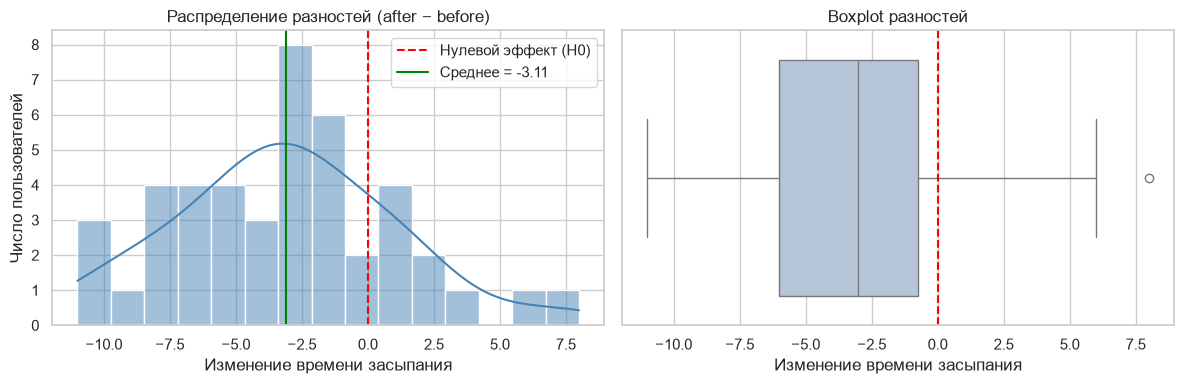

In [8]:
# ВАШ КОД: гистограмма с KDE и boxplot для diff
ig, axes = plt.subplots(1, 2, figsize=(12, 4))

# --- Гистограмма + плотность (KDE) ---
sns.histplot(df_clean["diff"], bins=15, kde=True, color="steelblue", ax=axes[0])
axes[0].axvline(0, color="red", linestyle="--", label="Нулевой эффект (H0)")
axes[0].axvline(df_clean["diff"].mean(), color="green", linestyle="-", label=f"Среднее = {df_clean['diff'].mean():.2f}")
axes[0].set_title("Распределение разностей (after − before)")
axes[0].set_xlabel("Изменение времени засыпания")
axes[0].set_ylabel("Число пользователей")
axes[0].legend()

# --- Boxplot ---
sns.boxplot(x=df_clean["diff"], color="lightsteelblue", ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Boxplot разностей")
axes[1].set_xlabel("Изменение времени засыпания")

plt.tight_layout()
plt.show()

**Описание графиков (2–3 предложения):**

1. Центр гистограммы сдвинут влево от нуля — среднее изменение отрицательное.
2. Распределение выглядит примерно колоколообразным, без резких выбросов, со смещением влево.

---
## Задание 4. Проверка нормальности разностей (2 балла)

**Что нужно сделать.** Выясните, можно ли считать разности `diff` приблизительно нормальными.

**Требования:**
1. Сформулируйте $H_0$ и $H_1$ для теста Шапиро-Уилка.
2. Проведите тест, выведите статистику $W$ и p-value.
3. Постройте Q-Q график (любой библиотекой).
4. Сформулируйте вывод (2–3 предложения): применим ли парный t-критерий? Что вы будете считать основным тестом, а что — проверочным?

### Подсказки

- Нормальность проверяется для **разностей**, а не для `before_min` и `after_min` по отдельности: парный t-тест — это тест для одной выборки `diff`.
- Тест: `stats.shapiro(...)`. Он возвращает статистику и p-value.
- Q-Q график: `stats.probplot(данные, dist="norm")` возвращает пару: теоретические и выборочные квантили, а также параметры прямой.
  Их можно нарисовать точками (`plotly` или `matplotlib`) и добавить линию.
- Помните: $p > 0.05$ означает «нет оснований отвергать нормальность», а не «нормальность доказана».
- Объём выборки (50) позволяет по центральной предельной теореме рассчитывать на приближённую нормальность среднего,
  даже если нормальность разностей не идеальна. Но график всё равно стоит посмотреть: нет ли сильных выбросов?

### Ваше решение

In [9]:
# ВАШ КОД: тест Шапиро-Уилка
shapiro_stat, shapiro_p = stats.shapiro(df_clean["diff"])

print(f"Статистика Шапиро-Уилка W = {shapiro_stat:.4f}")
print(f"p-value                  = {shapiro_p:.4f}")

if shapiro_p > ALPHA:
    print(f"\np > {ALPHA}: нет оснований отвергать нормальность разностей.")
else:
    print(f"\np <= {ALPHA}: нормальность разностей отвергается.")

Статистика Шапиро-Уилка W = 0.9786
p-value                  = 0.5786

p > 0.05: нет оснований отвергать нормальность разностей.


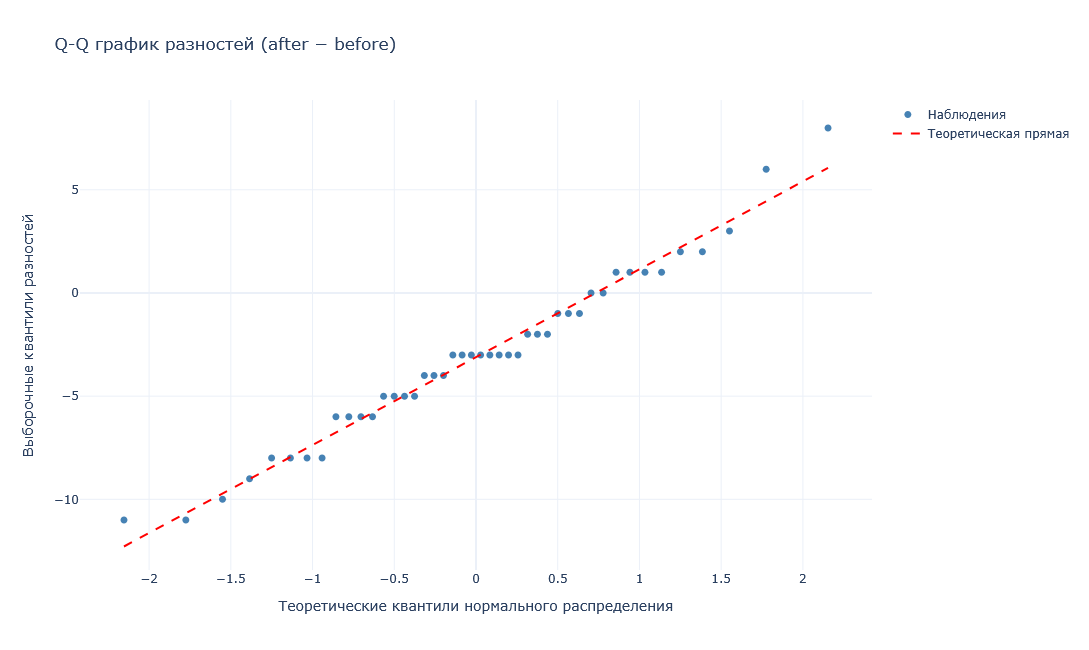

In [10]:
# ВАШ КОД: Q-Q график

(osm, osr), (slope, intercept, r) = stats.probplot(df_clean["diff"], dist="norm")

fig = go.Figure()
fig.add_trace(go.Scatter(x=osm, y=osr, mode="markers", name="Наблюдения",
                         marker=dict(size=7, color="steelblue")))
fig.add_trace(go.Scatter(x=osm, y=slope * osm + intercept, mode="lines",
                         name="Теоретическая прямая", line=dict(color="red", dash="dash")))

fig.update_layout(
    title="Q-Q график разностей (after − before)",
    xaxis_title="Теоретические квантили нормального распределения",
    yaxis_title="Выборочные квантили разностей",
    template="plotly_white",
    height=650,
)
fig.show()

**Гипотезы Шапиро-Уилка:**
Согласно критерия Шапиро-Уилка нормальность разностий не отвергается исходя из значения p-value 0.5786 > 0.05

**Вывод о нормальности и выборе тестов:** 
Парный t-тест применим, выполняются условия:
1. Нормальность распределения разностей согласно критерия Шапиро-Уилка
2. На граыфике Q-Q разностей есть незначительные отклонения значений от прямой. Сильные выбросы отсутсвуют.

---
## Задание 5. Парный t-критерий и доверительный интервал (2 балла)

**Что нужно сделать.** Проверьте гипотезу из задания 1 парным t-критерием.

**Требования:**
1. Посчитайте **вручную** (через `numpy`/`pandas`): среднее разностей $\bar d$, стандартное отклонение $s_d$,
   стандартную ошибку, статистику $t$ и число степеней свободы.
2. Получите p-value по распределению Стьюдента вручную (`scipy.stats.t`).
3. Проведите тест готовой функцией и убедитесь, что результаты совпадают.
4. Постройте двусторонний 95% доверительный интервал для $\mu_d$.
5. Запишите решение по правилу из задания 1 и интерпретацию в одном предложении.

### Подсказки

- Формула статистики: $t = \dfrac{\bar d}{s_d / \sqrt{n}}$, число степеней свободы $\text{df} = n - 1$.
- Стандартное отклонение выборки: `.std(ddof=1)` (в pandas `ddof=1` по умолчанию, в numpy — нет!).
- p-value вручную: используйте функцию выживания `stats.t.sf(...)` или функцию распределения `stats.t.cdf(...)`.
  Подумайте, какой «хвост» нужен для вашей $H_1$: левый или правый. Для левостороннего теста p-value равно $P(T \le t_{\text{набл}})$.
- Готовая функция: `stats.ttest_rel(a, b, alternative=...)`. Порядок аргументов важен: тест сравнивает `a` с `b`,
  а параметр `alternative` принимает `"two-sided"`, `"less"`, `"greater"`. Выберите значения так, чтобы они соответствовали вашей $H_1$.
- Доверительный интервал: `stats.t.interval(0.95, df=..., loc=среднее, scale=стандартная_ошибка)`.
- Если ваш ручной и готовый p-value не совпадают, проверьте знак $t$ и выбранный «хвост».

### Ваше решение

In [11]:
# ВАШ КОД: ручной расчёт (среднее, std, SE, t, df, p-value)
diff_mean = df_clean['diff'].mean()
diff_n = len(df_clean)
diff_std = df_clean['diff'].std(ddof=1)
std_err_rel = diff_std / np.sqrt(diff_n)
t = diff_mean / std_err_rel
df = diff_n - 1
p_val = stats.t.cdf(t, df=df)

print(f"Среднее разностей      = {diff_mean:.3f}")
print(f"Стандартное отклонение = {diff_std:.3f}")
print(f"Стандартная ошибка     = {std_err_rel:.3f}")
print(f"t-статистика           = {t:.3f}  (df = {df})")
print(f"p-value (вручную, H1: mu_d < 0) = {p_val:.6f}")

Среднее разностей      = -3.114
Стандартное отклонение = 4.183
Стандартная ошибка     = 0.631
t-статистика           = -4.937  (df = 43)
p-value (вручную, H1: mu_d < 0) = 0.000006


In [12]:
# ВАШ КОД: scipy.stats.ttest_rel и сверка с ручным расчётом
t_rel = stats.ttest_rel(df_clean["after_min"], df_clean["before_min"], alternative="less")
print(f"ttest_rel: t = {t_rel.statistic:.3f}, p-value = {t_rel.pvalue:.6f}")
print("Совпадает с ручным расчётом:", np.isclose(t_rel.pvalue, p_val))

ttest_rel: t = -4.937, p-value = 0.000006
Совпадает с ручным расчётом: True


In [13]:
# ВАШ КОД: 95% доверительный интервал для среднего эффекта
low, high = stats.t.interval(0.95, df=df, loc=diff_mean, scale=std_err_rel)
print(f"95% ДИ: [{low:.2f}; {high:.2f}]")

95% ДИ: [-4.39; -1.84]


**Решение по правилу и интерпретация:** 

При полученном значении p-value = 0.000006 есть основания отвергнуть гипотезу $H_0$ в пользу $H_1$ - Использование приложения сокращает время засыпания.
Доверительный интревал для средних значений изменения лежит целиком левее нуля, среднее значение изменения в него укладывается.

---
## Задание 6. Критерий Уилкоксона (1 балл)

**Что нужно сделать.** Повторите проверку непараметрическим критерием знаковых рангов и сравните с t-тестом.

**Требования:**
1. Запишите в одном предложении, что проверяет критерий Уилкоксона в этой задаче.
2. Проведите тест с той же альтернативой, что и в задании 5.
3. Сравните p-value двух тестов и напишите, согласуются ли выводы.

### Подсказки

- Функция: `stats.wilcoxon(...)`. Ей можно передать сразу столбец разностей.
- Параметр `alternative` работает так же, как у t-теста.
- Нулевые разности (участники без изменений) по умолчанию исключаются из расчёта. Это нормально; можно упомянуть в комментарии, сколько их было.
- Если p-value двух тестов отличаются в 1.5–3 раза, но решение одинаково, это не противоречие: тесты используют разную информацию.

### Ваше решение

In [14]:
# ВАШ КОД: критерий Уилкоксона
wx = stats.wilcoxon(df_clean['diff'], alternative="less")
#wx_rel = stats.wilcoxon(df_clean["after_min"], df_clean["before_min"], alternative="less")
print(f"wilcoxon: T = {wx.statistic:.3f}, p-value = {wx.pvalue:.6f}")

wilcoxon: T = 120.000, p-value = 0.000016


**Сравнение с t-тестом:**

Тест показал p-value несколько большее, чем показал парный t-критерий. Отличие менее чем в три раза. Значение p-value не превышает порог $\alpha$ = 0.05. Есть основания отвергнуть гипотезу $H_0$ в пользу $H_1$ - Использование приложения сокращает время засыпания. Разультаты парного t-теста и критерия Уилкосона согласуются.

---
## Задание 7. Типичная ошибка: непарный тест (2 балла)

**Что нужно сделать.** Намеренно примените **неверный** тест для независимых выборок и объясните разницу с результатом задания 5.

**Требования:**
1. Проведите тест Уэлча для двух независимых выборок (`before_min` и `after_min`) с той же альтернативой.
2. Выведите в таблице: $t$, p-value и стандартную ошибку для **парного** и **непарного** тестов, а также корреляцию Пирсона между `before_min` и `after_min`.
3. Изменилось ли решение по $H_0$ при $\alpha = 0.05$?
4. Объясните разницу в 3–4 предложениях: почему результаты различаются и какой тест надёжнее.
5. Постройте диаграмму рассеяния `before_min` vs `after_min` с диагональю $y = x$ и прокомментируйте её (1–2 предложения).

### Подсказки

- Функция: `stats.ttest_ind(a, b, equal_var=False, alternative=...)`. Порядок `a` и `b` должен быть таким же, как в задании 5.
- Стандартная ошибка непарного теста: $\sqrt{\dfrac{s_a^2}{n} + \dfrac{s_b^2}{n}}$. Стандартная ошибка парного теста: $s_d / \sqrt{n}$ (вы её уже считали).
- Корреляция: `df["before_min"].corr(df["after_min"])`.
- Для объяснения ответьте на вопросы: чем различаются люди между собой (сильно или слабо)? Сколько из этой вариации «вычитается» при переходе
  к разностям? Что происходит со знаменателем статистики $t$?
- Диаграмма рассеяния: `px.scatter` или `sns.scatterplot`. Диагональ: линия между точками `(min, min)` и `(max, max)`.
  Точки ниже диагонали — участники, у которых время засыпания уменьшилось.

### Ваше решение

In [15]:
# ВАШ КОД: непарный тест Уэлча
t_ind = stats.ttest_ind(df_clean["after_min"], df_clean["before_min"], alternative="less", equal_var=False)

std_a = df_clean['after_min'].std(ddof=1)
std_b = df_clean['before_min'].std(ddof=1)
n = len(df_clean['after_min'])
std_err_ind = np.sqrt(std_a**2 / n + std_b**2 / n)

corr = df_clean["before_min"].corr(df_clean["after_min"])

In [16]:
# ВАШ КОД: таблица сравнения (t, p-value, SE) и корреляция
t_comp_data = {
    'test': ['Парный', 'Непарный'],
    't': [t_rel.statistic, t_ind.statistic],
    'pvalue': [t_rel.pvalue, t_ind.pvalue],
    'SE': [std_err_rel, std_err_ind],
    'corr': [corr, corr]
}

comp_table = pd.DataFrame(t_comp_data)
comp_table

,test,t,pvalue,SE,corr
0,Парный,-4.937361,0.000006,0.630628,0.937178
1,Непарный,-1.271673,0.103472,2.448457,0.937178


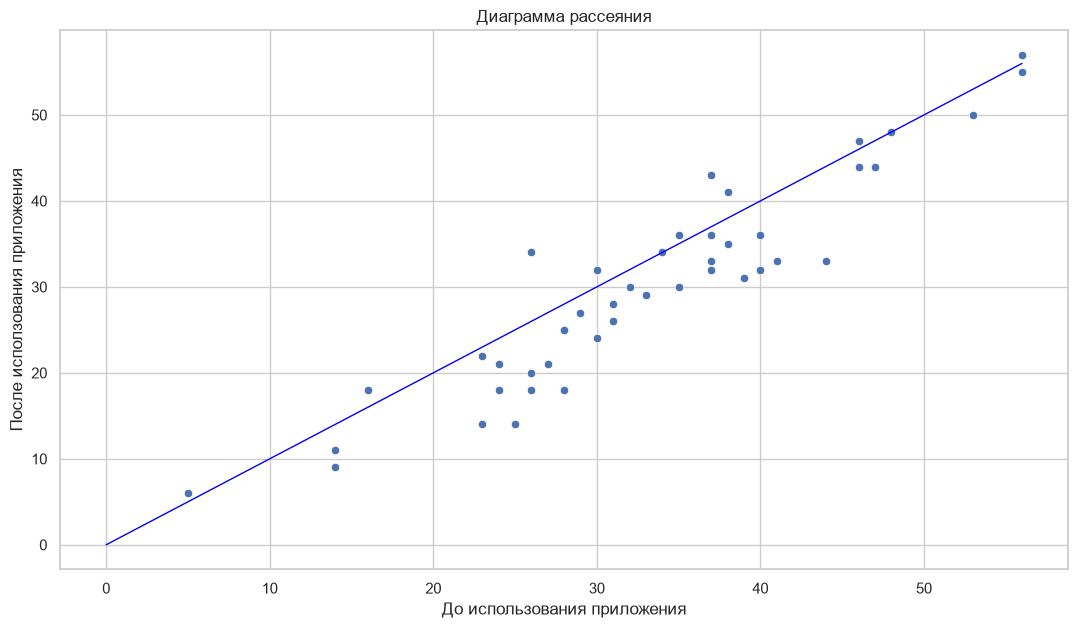

In [17]:
# ВАШ КОД: диаграмма рассеяния before vs after с диагональю y = x
lo_yx = 0
hi_yx = df_clean['before_min'].max()
fig, ax = plt.subplots(figsize=(13, 7))
sns.scatterplot(data=df_clean, x='before_min', y='after_min')
ax.plot([lo_yx, hi_yx], [lo_yx, hi_yx], color="blue", linestyle="-", linewidth=1.0, label="y = x")
plt.title('Диаграмма рассеяния')
plt.xlabel('До использования приложения')
plt.ylabel('После исползования приложения')
plt.show()

**Решение изменилось?** 

Непарный тест показал противоположные результаты, которые не согласуются с результатами двух предыдущих тестов (t-критерий и критерий Уилкоксона).

**Объяснение разницы (3–4 предложения):**

Непарныйе тест выдал противоречащий другим тестам результат, т.к. область применения непарного теста - независимые выборки. В текущем исследовании выборки зависимые, в выборке приводятся результаты для одной группы лиц до и после использования приложения, а не для разных групп лиц. Условия теста не соблюдены, не соблюдено условие независимости или непарности выборки, результат теста принять было бы не правильно.

**Комментарий к диаграмме:** 

Диаграмма рассеяния показывает увеличенную концентрацию точек ниже линии y=x. Отрицательной разности соответсвют точни ниже линии.

---
## Задание 8. Размер эффекта (1 балл)

**Что нужно сделать.** Оцените практическую значимость эффекта.

**Требования:**
1. Рассчитайте Cohen's $d$ для парных данных.
2. Интерпретируйте по шкале Коэна (≈0.2 — малый, ≈0.5 — средний, ≈0.8 — большой).
3. Выразите средний эффект в минутах и в процентах от среднего исходного времени засыпания.
4. Напишите 1–2 предложения: почему p-value недостаточно для ответа на вопрос «насколько это существенно?».

### Подсказки

- Формула: $d_z = \dfrac{\bar d}{s_d}$, где $\bar d$ и $s_d$ — среднее и стандартное отклонение разностей.
- У вас эффект отрицательный (время уменьшилось). Для интерпретации по шкале используйте **модуль** значения.
- Процент от исходного уровня: среднее изменение, делённое на `df["before_min"].mean()`, умноженное на 100.

### Ваше решение

In [18]:
# ВАШ КОД: Cohen's d и эффект в минутах / процентах
cohen_d = diff_mean / diff_std

def interpret_d(x):
    # Интерпретация по шкале Коэна
    x = abs(x)
    if x < 0.2:
        return "пренебрежимо малый"
    elif x < 0.5:
        return "малый"
    elif x < 0.8:
        return "средний"
    return "большой"


print(f"Cohen's d (парный) = {cohen_d:.3f}  ->  эффект {interpret_d(cohen_d)}")
print(f"Средний эффект в абсолютных величинах: {diff_mean:.2f} минуты (≈ {diff_mean / df_clean['before_min'].mean() * 100:.1f}% от исходного времени)")

Cohen's d (парный) = -0.744  ->  эффект средний
Средний эффект в абсолютных величинах: -3.11 минуты (≈ -9.4% от исходного времени)


**Интерпретация:** 
По шкале Коэна эффект средний. В абсолютных величинах среднее уменьшение времени засыпания составляет 3.11 минуты - это 9.4% от среднего времени засыпания до использования приложения.

---
## Задание 9. Гипотеза о доле улучшивших (1 балл)

**Что нужно сделать.** Проверьте ещё одну гипотезу, не использующую величину изменения, а только его **направление**:
*«более чем у половины участников время засыпания сократилось»*.

**Требования:**
1. Определите параметр $p$ и запишите $H_0$ и $H_1$.
2. Определите, кого учитывать в расчёте (что делать с участниками, у которых разность равна 0).
3. Проведите **биномиальный тест** и выведите p-value.
4. Сформулируйте вывод в одном предложении.
5. Рассчитайте долю улучшивших и её 95% доверительный интервал.

### Подсказки

- Параметр: $p$ — доля участников (среди тех, у кого время изменилось), у которых оно **сократилось**.
  Если приложение не работает, сокращение и увеличение равновероятны, то есть $p = 0.5$.
- Участников с `diff == 0` исключите из расчёта: они не дают информации о направлении. Укажите, сколько их было.
- Функция: `stats.binomtest(k, n, p=0.5, alternative=...)`, где `k` — число «успехов» (улучшившихся), `n` — число участников с ненулевой разностью.
- У результата теста есть метод `.proportion_ci(confidence_level=0.95)` для доверительного интервала доли. Внимание: интервал строится
  в соответствии с `alternative` теста (при односторонней альтернативе он тоже односторонний, одна из границ будет 0 или 1).
  Для обычного двустороннего интервала вызовите `binomtest` с `alternative="two-sided"`.
- Сравните этот тест с t-тестом: что он «теряет» по сравнению с ним (подсказка: он не учитывает величину изменений) и почему всё равно полезен
  (подсказка: не требует нормальности и устойчив к выбросам).

### Ваше решение

**Параметр, H₀ и H₁:**

Параметр p - отношение числа участников с уменьшением времени засыпания к числу участников с изменением времени засыпания.

$H_0$: Вероятность уменьшения времени засыпания равна p = 0.5 и не изменилась после использования приложения. Использование приложения не повлияло на время засыпания.

$H_1$: Вероятность уменьшения времени засыпания увеличилось и больше p = 0.5.

Согласно $H_1$ в параметре alternative указывается 'greater'

In [19]:
# ВАШ КОД: число улучшивших, число ненулевых разностей, биномиальный тест, ДИ доли
diff_number = len(df_clean[df_clean['diff'] != 0])
reduced_number = len(df_clean[df_clean['diff'] < 0])
if diff_number != 0:
    p_param = reduced_number / diff_number 
else:
    p_param = 0
    
print(f'число изменений: {diff_number}')
print(f'число уменьшений: {reduced_number}')
print(f'Параметр p: {p_param}')

b_test = stats.binomtest(reduced_number, diff_number, p=0.5, alternative='greater')
low, high = b_test.proportion_ci(confidence_level=0.95)

print(f'binomtest: T = {b_test.statistic:.3f}, p-value = {b_test.pvalue:.6f}')
print(f'ДИ для оценки доли (statistic) [{low:.3f}, {high:.3f}]')

число изменений: 42
число уменьшений: 33
Параметр p: 0.7857142857142857
binomtest: T = 0.786, p-value = 0.000136
ДИ для оценки доли (statistic) [0.656, 1.000]


**Вывод:**

Доверительный интервал [0.656, 1.000], p=0.5 не входит в ДИ - отклоняется гипотеза $H_0$ о неизменности времени засыпания после использования приложения.
p_value = 0.000136 - значительно меньше 0.05, Есть основания отклонить гипотезу $H_0$ в пользу $H_1$

---
## Задание 10. Итоговые выводы (1 балл)

**Что нужно сделать.** Подготовьте заключение для руководителя продукта (не статистика!).

**Требования.** Сводная таблица результатов и текст из 5–7 предложений, содержащий:
1. ответ на бизнес-вопрос и размер выборки после очистки (сколько участников вошло в анализ и сколько исключено);
2. величину эффекта с доверительным интервалом (в минутах);
3. долю участников, которым приложение помогло;
4. упоминание, что вывод устойчив (согласие нескольких тестов) или, наоборот, что есть расхождения;
5. **минимум два ограничения** исследования (подумайте про контрольную группу, длительность, самоотчёты участников, добровольность);
6. рекомендацию: что делать дальше.

### Подсказки

- Таблицу соберите через `pd.DataFrame` со столбцами: метод, статистика, p-value, решение при $\alpha$.
  Включите в неё и ошибочный непарный тест, пометив его.
- Пишите без жаргона: вместо «p < 0.05» — «различие вряд ли случайно».
- Помните, что **без контрольной группы** нельзя утверждать, что именно приложение привело к улучшению: на время засыпания могли повлиять
  другие факторы (сезон, привычки, ожидания участников).
- Хорошая рекомендация конкретна: например, «провести контролируемое исследование с группой сравнения», а не «нужно больше данных».

### Ваше решение

In [20]:
# ВАШ КОД: сводная таблица результатов
def solution(value):
    if value < ALPHA:
        return f'Отвергнуть H0 в пользу H1'
    else:
        return f'Принять H0'

results = {
    'Метод': ['Парный t-критерий', 'Непарный t-критерий', 'Критерий Уилкоксона', 'Биномиальный тест'],
    'Статистика': [t_rel.statistic, t_ind.statistic, wx.statistic, b_test.statistic],
    'p-value': [t_rel.pvalue, t_ind.pvalue, wx.pvalue, b_test.pvalue],
    f'Решение при ALPHA = {ALPHA}': [solution(t_rel.pvalue), solution(t_ind.pvalue), solution(wx.pvalue), solution(b_test.pvalue)],
    'Корректность': ['', 'Ошибочный', '', '']
}

df_result = pd.DataFrame(results)
df_result

,Метод,Статистика,p-value,Решение при ALPHA = 0.05,Корректность
0,Парный t-критерий,-4.937361,0.000006,Отвергнуть H0 в пользу H1,
1,Непарный t-критерий,-1.271673,0.103472,Принять H0,Ошибочный
2,Критерий Уилкоксона,120.000000,0.000016,Отвергнуть H0 в пользу H1,
3,Биномиальный тест,0.785714,0.000136,Отвергнуть H0 в пользу H1,


### Заключение для руководителя

...

---
## ★ Бонусное задание (+2 балла): одинаково ли приложение помогает разным возрастным группам?

**Что нужно сделать.** Выясните, различается ли средний эффект приложения между группами `до 35` и `35 и старше`, созданными вами в задании 2. Участников с неизвестным возрастом (`age_group` пропущен) исключите из этого задания и укажите, сколько их.

**Требования:**
1. Сформулируйте $H_0$ и $H_1$ (параметры: средние разности $\mu_{d,\text{до 35}}$ и $\mu_{d,\text{35+}}$). Выберите тип альтернативы и обоснуйте.
2. Постройте график (boxplot или violin) разностей `diff` по группам.
3. Для **каждой группы отдельно** выполните парный t-тест (помните про множественные проверки: как изменится порог значимости, если вы делаете 2 проверки?).
4. Сравните эффект между группами: проверьте нормальность `diff` в каждой группе, затем проведите подходящий тест для **двух независимых** выборок
   (какие это выборки теперь — парные или независимые, и почему?).
5. Сформулируйте вывод в 2–3 предложениях.

### Подсказки

- Здесь «объектами» сравнения становятся **разности** двух разных групп людей, а группы людей между собой независимы.
- Разбить данные: `df_clean[df_clean["age_group"] == "до 35"]["diff"]` или `df_clean.groupby("age_group")["diff"]`. Строки с пропуском в `age_group` при `groupby` по умолчанию отбрасываются, а при фильтрации по условию `!= "до 35"` они, наоборот, попадут во вторую группу, поэтому сравнивайте с обеими группами явно.
- Для сравнения двух независимых групп: `stats.ttest_ind(..., equal_var=False)` (Уэлч) и/или `stats.mannwhitneyu(...)`.
- Поправка Бонферрони: делите $\alpha$ на число проверок.
- В выводе укажите не только «различаются ли», но и **на сколько минут** различаются средние эффекты.

### Ваше решение

In [21]:
# ВАШ КОД: бонусное задание

**Гипотезы и вывод:** ...

---
## Задание 11. Оформление проекта (2 балла)

Итоговая работа сдаётся не просто файлом, а как **готовый воспроизводимый проект**. Требования см. в разделе «Что сдавать» ниже.

---
## Чек-лист самопроверки перед сдачей

**Анализ**
- [ ] Данные очищены по правилам 1–4 в правильном порядке; контрольные числа (44 строки, 40 заполненных `age_group`) совпали; ведётся журнал очистки.
- [ ] Столбец `age_group` создан корректно: возраст ровно 35 попадает в «35 и старше», пропуски возраста остались пропусками.
- [ ] Все задания 3–10 выполнены на `df_clean`, а не на исходном `df`.
- [ ] Гипотезы записаны формулами, определена разность и параметр $\mu_d$.
- [ ] Направление $H_1$ согласовано со знаком разности `after − before` и параметром `alternative` во **всех** тестах.
- [ ] Нормальность проверена для разностей, а не для исходных столбцов.
- [ ] Ручной расчёт t-критерия совпадает с `ttest_rel`.
- [ ] Для непарного теста порядок аргументов тот же, что и для парного.
- [ ] Все графики подписаны (заголовок, оси).
- [ ] Выводы написаны простым языком и содержат ограничения исследования.
- [ ] Ноутбук выполняется целиком без ошибок (**Restart & Run All**).

**Проект**
- [ ] Репозиторий публичный: ссылка открывается без авторизации (проверьте в режиме инкогнито).
- [ ] В репозитории есть `.ipynb`, `requirements.txt` и `README.md`.
- [ ] В чистом окружении работает цепочка: `pip install -r requirements.txt` → открыть ноутбук → Restart & Run All.
- [ ] Ссылка отправлена не позднее чем за 3 дня до защиты.

---
## Что сдавать

1. **Оформить итог отдельным проектом**, в котором будет `.ipynb` с вашим решением.
2. **В проекте должен быть файл `requirements.txt`** со всеми необходимыми библиотеками.
3. **Расположить проект на GitHub** (или аналоге: GitLab, Bitbucket) **в виде публичного репозитория**.
4. **Предоставить ссылку на GitHub-репозиторий не позднее чем за 3 дня до защиты проекта.**

### Рекомендации по оформлению

**Структура репозитория:**

```
project-name/
├── README.md          # краткое описание проекта, как запустить, главные выводы
├── requirements.txt   # зависимости
└── solution.ipynb     # ваше решение
```

Отдельный файл с данными не нужен: данные создаются ячейкой генерации внутри ноутбука.

**`README.md`** (достаточно 5–10 строк): название и цель проекта, краткое описание данных, как установить зависимости и запустить ноутбук,
главный вывод (1–2 предложения).

**`requirements.txt`:**
- перечислите библиотеки, которые **реально используются** в вашем ноутбуке (по одной на строку); не копируйте вслепую полный вывод `pip freeze`;
- подумайте, какие библиотеки нужны не для самого анализа, а для **работы ноутбука**: например, `plotly` требует `nbformat` для отображения графиков в Jupyter;
- рекомендуется указывать версии (например, `pandas>=2.0`): узнать установленную версию можно через `pip show имя_библиотеки` или `pip list`.

**Проверка воспроизводимости.** Создайте чистое виртуальное окружение (`python -m venv .venv`), установите зависимости командой `pip install -r requirements.txt`
и выполните ноутбук командой **Restart & Run All**. Если появилась ошибка `ModuleNotFoundError`, значит, в `requirements.txt` не хватает библиотеки.

**Что не стоит публиковать:** папку виртуального окружения (`.venv`), личные токены и пароли. Для исключения лишнего добавьте файл `.gitignore`.

**Срок.** Ссылку на репозиторий нужно отправить **не позднее чем за 3 дня до защиты**. Репозиторий должен оставаться неизменным до защиты, чтобы защищаемая версия совпадала с проверенной.